# Bagian E3: Naïve Bayes untuk Prediksi Diabetes

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmad-fathan/Fundamentals-of-Data-Science/blob/main/Classification/bab-e3-naive-bayes-prediksi-diabetes.ipynb)

Bagian ini menerapkan **Gaussian Naïve Bayes** pada data kesehatan. Tugasnya adalah memperkirakan apakah seorang pasien mengidap diabetes berdasarkan hasil pemeriksaan sederhana. Langkahnya sama dengan Bagian E1:

1. memuat dan mengenal dataset,
2. melihat sebaran setiap fitur,
3. membagi data latih dan data uji,
4. melatih model dan memprediksi seorang pasien baru,
5. mengevaluasi model dan melihat mengapa akurasi saja menyesatkan pada data tidak seimbang.

Jalankan cell secara berurutan dari atas ke bawah. Perkiraan waktu: 25 sampai 30 menit.

## E3.1 Mengimpor Library

In [1]:
%matplotlib inline
import pandas as pd                     # tabel data (DataFrame)
import matplotlib.pyplot as plt         # visualisasi

from sklearn.model_selection import train_test_split    # membagi data latih dan uji
from sklearn.naive_bayes import GaussianNB              # Naive Bayes untuk fitur angka
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

print("Library berhasil diimpor")

Library berhasil diimpor


## E3.2 Mengenal Dataset Diabetes

Dataset ini berisi 100.000 catatan pasien dari Kaggle, *Diabetes Prediction Dataset* (iammustafatz). Label `diabetes = 1` berarti pasien mengidap diabetes, dan `diabetes = 0` berarti tidak.

Fitur yang dipakai semuanya berupa angka:

- `age` = usia (tahun)
- `hypertension` = riwayat hipertensi (1 = ya, 0 = tidak)
- `heart_disease` = riwayat penyakit jantung (1 = ya, 0 = tidak)
- `bmi` = indeks massa tubuh
- `HbA1c_level` = rata-rata kadar gula darah 2–3 bulan terakhir (persen)
- `blood_glucose_level` = kadar gula darah saat pemeriksaan (mg/dL)

In [2]:
url = ("https://raw.githubusercontent.com/ahmad-fathan/Fundamentals-of-Data-Science/"
       "main/Classification/diabetes_prediction_dataset.csv.gz")
diabetes = pd.read_csv(url)

print("Ukuran data:", diabetes.shape)
diabetes.head()

Ukuran data: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


diabetes
0    91500
1     8500
Name: count, dtype: int64


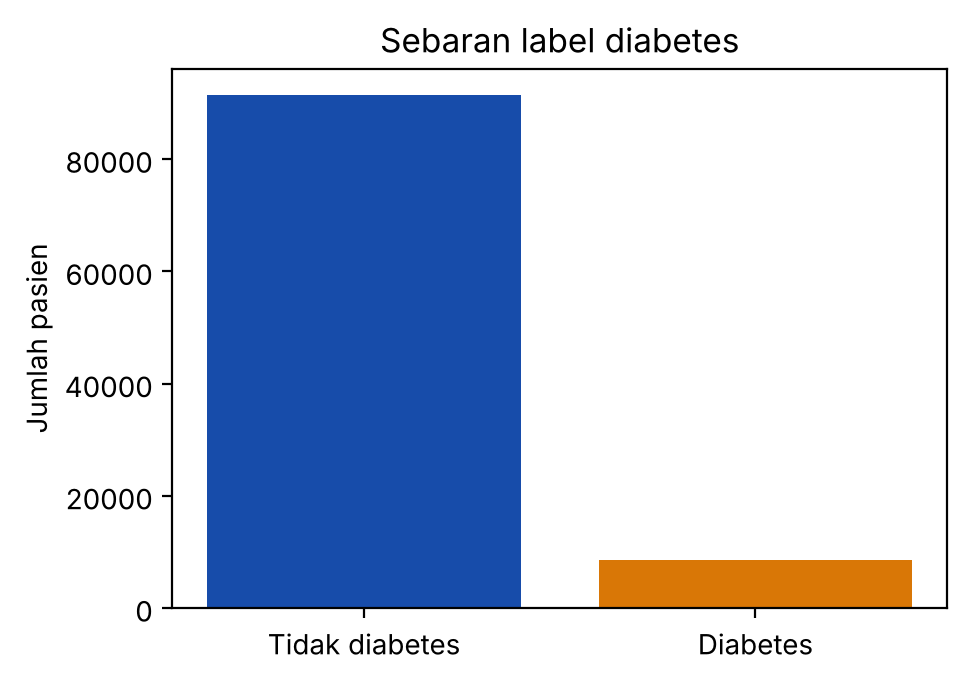

In [3]:
jumlah = diabetes["diabetes"].value_counts().sort_index()
print(jumlah)

plt.figure(figsize=(5, 3.5))
plt.bar(["Tidak diabetes", "Diabetes"], jumlah.values, color=["#174CAA", "#D97706"])
plt.ylabel("Jumlah pasien")
plt.title("Sebaran label diabetes")
plt.show()

Hanya sekitar **8,5 persen** pasien yang mengidap diabetes, sehingga data ini **tidak seimbang**. Model yang selalu menjawab "tidak diabetes" sudah benar sekitar 91,5 persen, padahal tidak pernah menemukan satu pasien diabetes pun. Angka ini akan dipakai sebagai pembanding di E3.6.

## E3.3 Melihat Sebaran Setiap Fitur

Histogram berikut membandingkan sebaran kedua kelas untuk setiap fitur.

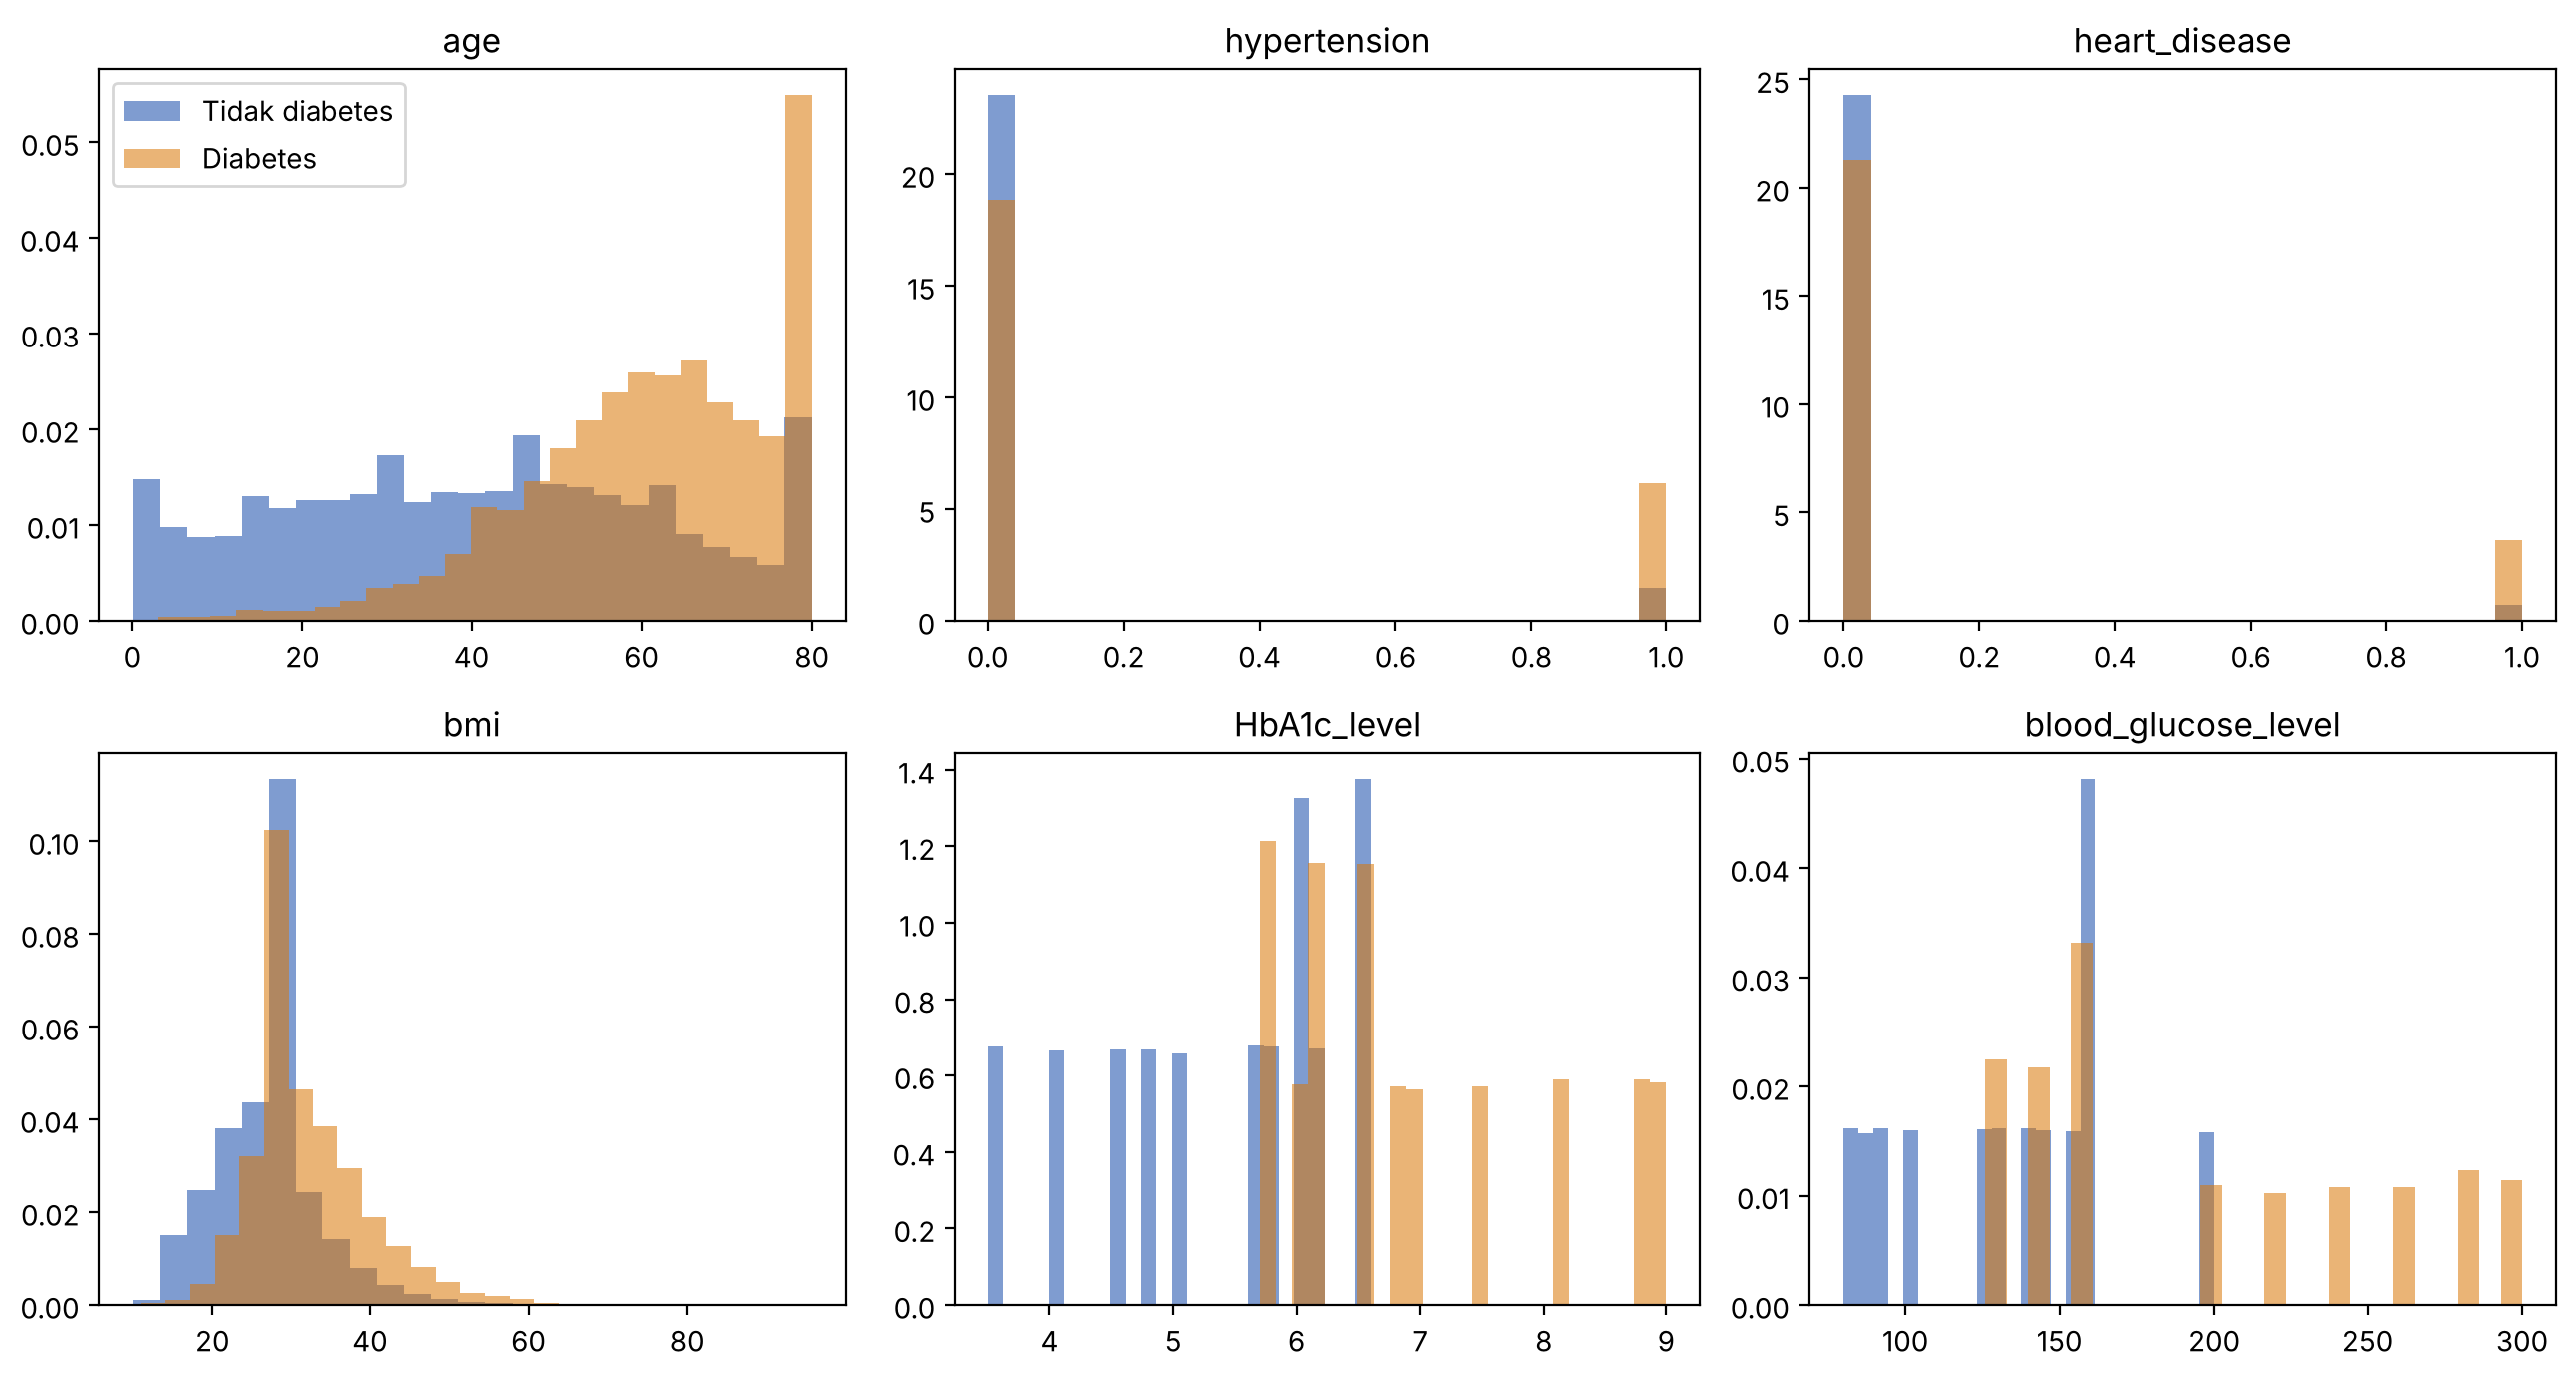

In [4]:
fitur = ["age", "hypertension", "heart_disease", "bmi", "HbA1c_level", "blood_glucose_level"]
warna = {0: "#174CAA", 1: "#D97706"}
label = {0: "Tidak diabetes", 1: "Diabetes"}

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, f in zip(axes.ravel(), fitur):
    for k in (0, 1):
        nilai = diabetes.loc[diabetes["diabetes"] == k, f]
        ax.hist(nilai, bins=25, alpha=0.55, color=warna[k], label=label[k], density=True)
    ax.set_title(f)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**HbA1c dan gula darah memisahkan kedua kelas dengan paling jelas**: puncak pasien diabetes bergeser jauh ke kanan. Usia dan BMI juga bergeser, tetapi kedua kelas masih banyak bertumpuk.

## E3.4 Membagi Data Latih dan Data Uji

Data dibagi menjadi 80 persen data latih dan 20 persen data uji. `stratify=y` menjaga proporsi pasien diabetes tetap sama di kedua bagian.

In [5]:
X = diabetes[fitur]         # fitur
y = diabetes["diabetes"]    # target: 0 atau 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Data latih:", X_train.shape, "| data uji:", X_test.shape)

Data latih: (80000, 6) | data uji: (20000, 6)


## E3.5 Melatih Model dan Memprediksi Pasien Baru

Sama seperti di Bagian E1, `GaussianNB` mempelajari rata-rata dan standar deviasi setiap fitur untuk setiap kelas, ditambah prior setiap kelas.

In [6]:
model = GaussianNB()
model.fit(X_train, y_train)

print("Model selesai dilatih. Kelas:", model.classes_)

Model selesai dilatih. Kelas: [0 1]


Misalkan seorang pasien berusia 55 tahun datang dengan hasil pemeriksaan berikut. Nilainya sengaja dipilih di antara kedua kelas.

In [7]:
pasien = pd.DataFrame([{
    "age": 55.0,
    "hypertension": 0,
    "heart_disease": 0,
    "bmi": 28.0,
    "HbA1c_level": 7.2,
    "blood_glucose_level": 170,
}])

proba = model.predict_proba(pasien)[0]
print("Probabilitas [tidak diabetes, diabetes]:", proba.round(3))
print("Prediksi:", model.predict(pasien)[0])

Probabilitas [tidak diabetes, diabetes]: [0.89 0.11]
Prediksi: 0


**Hasil yang diharapkan:** model menjawab "tidak diabetes" (kelas 0) dengan probabilitas sekitar 0,89, meskipun HbA1c dan gula darahnya di atas normal. Penyebabnya adalah **prior**: pasien tanpa diabetes jauh lebih banyak di data latih (sekitar 91,5 persen). Ketika bukti dari fitur belum cukup kuat, prior yang besar ikut menentukan keputusan.

## E3.6 Mengevaluasi Model

Sekarang kinerja model diukur pada data uji, yaitu 20.000 pasien yang tidak dilihat model saat training.

In [8]:
y_pred = model.predict(X_test)

print(f"Akurasi data uji: {accuracy_score(y_test, y_pred):.3f}")
print()
print(classification_report(y_test, y_pred, digits=3,
                            target_names=["tidak diabetes", "diabetes"]))

Akurasi data uji: 0.905

                precision    recall  f1-score   support

tidak diabetes      0.967     0.928     0.947     18300
      diabetes      0.458     0.656     0.540      1700

      accuracy                          0.905     20000
     macro avg      0.712     0.792     0.743     20000
  weighted avg      0.923     0.905     0.912     20000



Akurasi sekitar **0,905** terlihat tinggi, tetapi model pembanding yang selalu menjawab "tidak diabetes" sudah mendapat **0,915**. Jadi, akurasi saja menyesatkan.

Lihat baris kelas diabetes. *Recall* sekitar 0,66 berarti model menemukan sekitar dua pertiga pasien diabetes, sesuatu yang tidak dilakukan model pembanding. *Precision* sekitar 0,46 berarti kurang dari separuh pasien yang dinyatakan diabetes benar-benar mengidap diabetes. Untuk skrining awal, *recall* biasanya lebih penting, karena pasien yang terlewat lebih berisiko daripada pasien yang perlu diperiksa ulang.

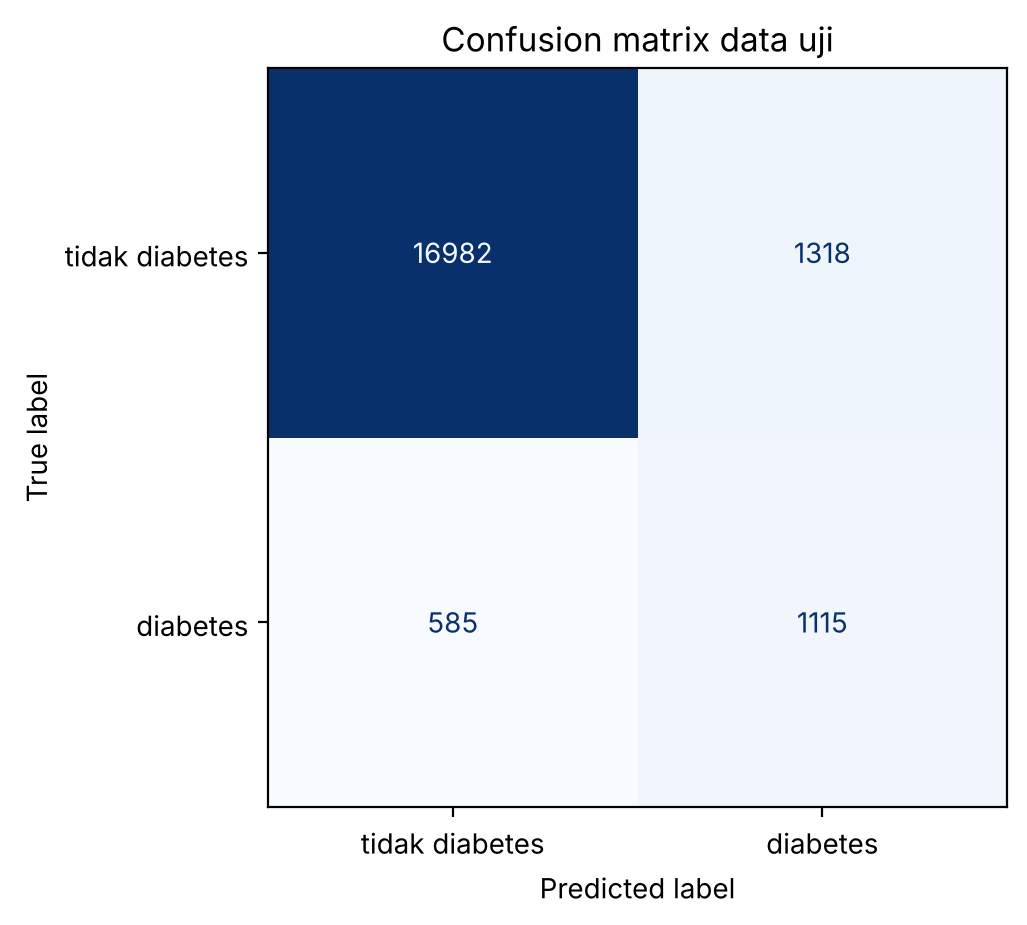

In [9]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", colorbar=False,
                                        display_labels=["tidak diabetes", "diabetes"])
plt.title("Confusion matrix data uji")
plt.show()

Angka di diagonal adalah prediksi yang benar. Kesalahannya ada dua jenis:

- **1.318 pasien sehat** ditebak mengidap diabetes (salah alarm).
- **585 pasien diabetes** ditebak sehat (*false negative*). Inilah kesalahan yang paling berbahaya dalam konteks kesehatan.

## E3.7 Latihan

Kerjakan latihan berikut di cell kosong yang tersedia.

**Latihan 1.** Latih `GaussianNB` yang hanya memakai **satu** fitur, yaitu `HbA1c_level`, dengan pembagian data yang sama. Tampilkan `classification_report`, lalu bandingkan akurasi dan *recall* kelas diabetes dengan model enam fitur.

*Hasil yang diharapkan:* akurasi sekitar 0,93, lebih tinggi daripada model enam fitur, tetapi *recall* kelas diabetes hanya sekitar 0,23 (model enam fitur 0,66). Jelaskan mengapa akurasi bisa naik sementara *recall* justru turun jauh.

In [10]:
# Latihan 1


**Latihan 2.** Ulangi Latihan 1 dengan fitur `blood_glucose_level`. Fitur mana yang lebih berguna jika dipakai sendirian? Apakah jawaban Anda sesuai dengan histogram di E3.3?

In [11]:
# Latihan 2


Pada data yang tidak seimbang, akurasi saja tidak cukup. Pilih metrik evaluasi yang sesuai dengan kesalahan yang paling ingin dihindari.